# Tacotron: Towards End-to-End Speech Synthesis

**Paper:** [arXiv:1703.10135](https://arxiv.org/abs/1703.10135) — Wang et al., Google, 2017

This notebook implements a simplified **Tacotron** model from scratch in PyTorch: a character-to-mel-spectrogram
sequence-to-sequence model with attention, a CBHG encoder, a CBHG post-processing net, and Griffin-Lim
waveform synthesis. We train on a **toy dataset** (synthetic audio signals paired with character sequences)
to demonstrate the architecture and visualize the learned attention alignment.

**Key architectural components:**
1. **CBHG module** — Convolution Bank + Highway network + Bidirectional GRU
2. **Encoder** — Character embedding → PreNet → CBHG
3. **Attention Decoder** — Content-based tanh attention, GRU decoder with reduction factor r=2
4. **Post-processing net** — CBHG that refines mel-spectrogram with bidirectional context
5. **Griffin-Lim** — Convert predicted spectrogram to waveform


## 1. Setup and Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from collections import OrderedDict
import random, math, warnings
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Try to install librosa for mel-spectrogram and Griffin-Lim
try:
    import librosa
    import librosa.display
    HAS_LIBROSA = True
    print('librosa available')
except ImportError:
    HAS_LIBROSA = False
    print('librosa not available — using numpy-based spectrogram')


Device: cuda
GPU: Tesla T4
librosa available


## 2. Character Processing and Vocabulary

Tacotron takes raw characters as input. We build a simple character vocabulary.

In [2]:
CHARS = 'abcdefghijklmnopqrstuvwxyz !.,?0123456789'
CHAR_TO_IDX = {c: i for i, c in enumerate(CHARS)}
IDX_TO_CHAR = {i: c for i, c in enumerate(CHARS)}
VOCAB_SIZE = len(CHARS)
EMBED_DIM = 256  # paper uses 256-D character embedding

print(f'Vocabulary size: {VOCAB_SIZE}')
print(f'Characters: {repr(CHARS)}')

def text_to_indices(text):
    """Convert a text string to a list of character indices."""
    text = text.lower()
    return [CHAR_TO_IDX[c] for c in text if c in CHAR_TO_IDX]

# Example
sample_text = 'hello world'
sample_idx = text_to_indices(sample_text)
print(f'"{sample_text}" -> {sample_idx}')


Vocabulary size: 41
Characters: 'abcdefghijklmnopqrstuvwxyz !.,?0123456789'
"hello world" -> [7, 4, 11, 11, 14, 26, 22, 14, 17, 11, 3]


## 3. Pre-Net Module

A bottleneck FC layer with dropout. Applied to both encoder input (character embeddings) and
decoder input (mel frames). The dropout (0.5) is **critical** — it acts as a noise source that
helps the model generalize to the multi-modal output distribution of speech.

In [3]:
class PreNet(nn.Module):
    """Two FC layers with ReLU and 50% dropout (applied at train AND inference)."""
    def __init__(self, in_dim, hidden_dims=(256, 128), dropout=0.5):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dims[0])
        self.fc2 = nn.Linear(hidden_dims[0], hidden_dims[1])
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x):
        # x: (B, T, in_dim) or (B, in_dim)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.dropout(F.relu(self.fc2(x)))
        return x

# Test
prenet = PreNet(256, (256, 128))
test_input = torch.randn(2, 5, 256)
test_output = prenet(test_input)
print(f'PreNet: {test_input.shape} -> {test_output.shape}')


PreNet: torch.Size([2, 5, 256]) -> torch.Size([2, 5, 128])


## 4. CBHG Module

**C**onvolution **B**ank + **H**ighway network + bidirectional **G**RU.

This is the core building block used in both the encoder and post-processing net:
- **Conv1D bank**: K sets of 1-D convolutions with widths 1..K, modeling unigrams through K-grams
- **Max pooling**: stride=1, preserves time resolution, adds local invariance
- **Conv1D projections**: with residual connection
- **Highway network**: 4 layers with gate mechanisms for gradient flow
- **Bidirectional GRU**: captures forward and backward sequential context

In [4]:
class HighwayLayer(nn.Module):
    """Highway network layer: y = T*H(x) + (1-T)*x where T is a transform gate."""
    def __init__(self, dim):
        super().__init__()
        self.transform = nn.Linear(dim, dim)
        self.gate = nn.Linear(dim, dim)
        
    def forward(self, x):
        T = torch.sigmoid(self.gate(x))  # transform gate
        H = F.relu(self.transform(x))    # transform
        return T * H + (1 - T) * x       # carry + transform

class CBHG(nn.Module):
    """CBHG: Convolution Bank + Highway network + Bidirectional GRU."""
    def __init__(self, in_dim, K=8, conv_channels=32, highway_layers=1, gru_cells=64):
        super().__init__()
        self.K = K
        
        # Conv1D bank: K sets of 1-D convolutions with widths 1..K
        self.conv_bank = nn.ModuleList([
            nn.Conv1d(in_dim, conv_channels, kernel_size=k, padding=k//2)
            for k in range(1, K + 1)
        ])
        bank_out_dim = conv_channels * K
        
        # Max pooling (stride=1, width=2) + Conv1D projections with residual
        self.conv_proj1 = nn.Conv1d(bank_out_dim, conv_channels, kernel_size=3, padding=1)
        self.conv_proj2 = nn.Conv1d(conv_channels, in_dim, kernel_size=3, padding=1)
        self.batch_norm1 = nn.BatchNorm1d(bank_out_dim)
        self.batch_norm2 = nn.BatchNorm1d(in_dim)
        
        # Highway network
        self.highway = nn.ModuleList([HighwayLayer(in_dim) for _ in range(highway_layers)])
        
        # Bidirectional GRU
        self.gru = nn.GRU(in_dim, gru_cells, batch_first=True, bidirectional=True)
        
    def forward(self, x):
        # x: (B, T, in_dim)
        B, T, D = x.shape
        
        # Conv bank: apply each conv, stack along channel dim
        x_t = x.transpose(1, 2)  # (B, in_dim, T)
        conv_outputs = []
        for conv in self.conv_bank:
            out = conv(x_t)  # (B, conv_channels, T')
            # Trim to original T if padding expanded it
            if out.size(2) > T:
                out = out[:, :, :T]
            elif out.size(2) < T:
                out = F.pad(out, (0, T - out.size(2)))
            conv_outputs.append(out)
        conv_bank_out = torch.cat(conv_outputs, dim=1)  # (B, K*conv_channels, T)
        conv_bank_out = F.relu(self.batch_norm1(conv_bank_out))
        
        # Max pooling (stride=1, width=2)
        pooled = F.max_pool1d(conv_bank_out, kernel_size=2, stride=1, padding=1)
        if pooled.size(2) > T:
            pooled = pooled[:, :, :T]
        elif pooled.size(2) < T:
            pooled = F.pad(pooled, (0, T - pooled.size(2)))
        
        # Conv projections with residual
        proj = F.relu(self.conv_proj1(pooled))
        proj = self.batch_norm2(self.conv_proj2(proj))  # (B, in_dim, T)
        residual = proj + x_t  # residual connection
        
        # Highway layers
        hw_input = residual.transpose(1, 2)  # (B, T, in_dim)
        for hw in self.highway:
            hw_input = hw(hw_input)
        
        # Bidirectional GRU
        out, _ = self.gru(hw_input)  # (B, T, 2*gru_cells)
        return out

# Test
cbhg = CBHG(in_dim=128, K=8, conv_channels=32, highway_layers=1, gru_cells=64)
test_input = torch.randn(2, 10, 128)
test_output = cbhg(test_input)
print(f'CBHG: {test_input.shape} -> {test_output.shape}')  # (2, 10, 256)


CBHG: torch.Size([2, 10, 128]) -> torch.Size([2, 10, 128])


## 5. Encoder

Character embedding → PreNet → CBHG. Produces the encoder representation that the attention module attends over.

In [5]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, embed_dim=256, prenet_dims=(256, 128),
                 cbhg_K=4, cbhg_channels=64, cbhg_highway=2, cbhg_gru=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.prenet = PreNet(embed_dim, prenet_dims, dropout=0.5)
        self.cbhg = CBHG(prenet_dims[1], K=cbhg_K, conv_channels=cbhg_channels,
                         highway_layers=cbhg_highway, gru_cells=cbhg_gru)
        
    def forward(self, text_indices):
        # text_indices: (B, T_text)
        x = self.embedding(text_indices)  # (B, T_text, embed_dim)
        x = self.prenet(x)                # (B, T_text, prenet_dims[1])
        x = self.cbhg(x)                  # (B, T_text, 2*cbhg_gru)
        return x

# Test
encoder = Encoder(VOCAB_SIZE)
test_indices = torch.randint(0, VOCAB_SIZE, (2, 15))
enc_out = encoder(test_indices)
print(f'Encoder: {test_indices.shape} -> {enc_out.shape}')  # (2, 15, 256)


Encoder: torch.Size([2, 15]) -> torch.Size([2, 15, 256])


## 6. Attention Decoder

Content-based tanh attention with a GRU decoder. Key features:
- **Attention RNN**: GRU that produces the query at each decoder step
- **Content-based attention**: score = tanh(W_q·query + W_k·keys), then softmax
- **Decoder RNN**: 2-layer residual GRU stack
- **Reduction factor r=2**: Predicts 2 mel frames per decoder step
- **Teacher forcing**: Every r-th ground truth frame is fed as decoder input

In [6]:
class AttentionDecoder(nn.Module):
    def __init__(self, encoder_dim=256, decoder_dim=256, attention_dim=128,
                 mel_dim=80, r=2, prenet_dims=(256, 128)):
        super().__init__()
        self.mel_dim = mel_dim
        self.r = r
        self.decoder_dim = decoder_dim
        
        # PreNet for decoder input
        self.prenet = PreNet(mel_dim, prenet_dims, dropout=0.5)
        
        # Attention RNN (produces query)
        self.attention_rnn = nn.GRUCell(prenet_dims[1] + encoder_dim, decoder_dim)
        
        # Attention scoring
        self.query_proj = nn.Linear(decoder_dim, attention_dim, bias=False)
        self.key_proj = nn.Linear(encoder_dim, attention_dim, bias=False)
        
        # Decoder RNNs (2-layer residual GRU)
        self.decoder_rnn1 = nn.GRUCell(decoder_dim + encoder_dim, decoder_dim)
        self.decoder_rnn2 = nn.GRUCell(decoder_dim, decoder_dim)
        
        # Output projection: decoder_dim -> r * mel_dim
        self.output_proj = nn.Linear(decoder_dim, r * mel_dim)
        
    def forward(self, encoder_outputs, mel_targets=None, teacher_forcing=True,
                max_decoder_steps=200):
        """
        encoder_outputs: (B, T_enc, encoder_dim)
        mel_targets: (B, T_mel, mel_dim) or None (for inference)
        Returns: mel_outputs (B, T_dec, mel_dim), attention_weights list
        """
        B = encoder_outputs.size(0)
        T_enc = encoder_outputs.size(1)
        device = encoder_outputs.device
        
        # Precompute attention keys
        keys = self.key_proj(encoder_outputs)  # (B, T_enc, attention_dim)
        
        # Initialize decoder state
        h_attn = torch.zeros(B, self.decoder_dim, device=device)
        h_dec1 = torch.zeros(B, self.decoder_dim, device=device)
        h_dec2 = torch.zeros(B, self.decoder_dim, device=device)
        
        # GO frame (all zeros)
        go_frame = torch.zeros(B, self.mel_dim, device=device)
        
        mel_outputs = []
        all_attentions = []
        
        # First input is GO frame
        current_input = go_frame
        
        if teacher_forcing and mel_targets is not None:
            # Training: use ground truth frames as input (teacher forcing)
            T_mel = mel_targets.size(1)
            n_steps = T_mel // self.r
            
            for t in range(n_steps):
                # PreNet on current input frame
                prenet_out = self.prenet(current_input)  # (B, prenet_dims[1])
                
                # Attention RNN
                h_attn = self.attention_rnn(
                    torch.cat([prenet_out, self._attend(h_attn, keys, encoder_outputs, all_attentions)], dim=1),
                    h_attn
                )
                
                # Get context vector from attention
                context = self._get_context(h_attn, keys, encoder_outputs, all_attentions)
                
                # Decoder RNNs (residual)
                h_dec1 = self.decoder_rnn1(torch.cat([h_attn, context], dim=1), h_dec1)
                h_dec2 = self.decoder_rnn2(h_dec1, h_dec2)
                h_dec2 = h_dec2 + h_dec1  # residual connection
                
                # Output projection: predict r mel frames
                output = self.output_proj(h_dec2)  # (B, r * mel_dim)
                output = output.view(B, self.r, self.mel_dim)
                mel_outputs.append(output)
                
                # Next input: every r-th ground truth frame
                next_idx = (t + 1) * self.r
                if next_idx < T_mel:
                    current_input = mel_targets[:, next_idx, :]
                else:
                    current_input = output[:, -1, :].detach()  # use last prediction
        else:
            # Inference: autoregressive
            for t in range(max_decoder_steps):
                prenet_out = self.prenet(current_input)
                h_attn = self.attention_rnn(
                    torch.cat([prenet_out, self._attend(h_attn, keys, encoder_outputs, all_attentions)], dim=1),
                    h_attn
                )
                context = self._get_context(h_attn, keys, encoder_outputs, all_attentions)
                h_dec1 = self.decoder_rnn1(torch.cat([h_attn, context], dim=1), h_dec1)
                h_dec2 = self.decoder_rnn2(h_dec1, h_dec2)
                h_dec2 = h_dec2 + h_dec1
                output = self.output_proj(h_dec2)
                output = output.view(B, self.r, self.mel_dim)
                mel_outputs.append(output)
                current_input = output[:, -1, :].detach()
        
        mel_outputs = torch.cat(mel_outputs, dim=1)  # (B, T_dec, mel_dim)
        attention = torch.stack(all_attentions, dim=1)  # (B, n_steps, T_enc)
        return mel_outputs, attention
    
    def _attend(self, query, keys, encoder_outputs, attn_list):
        """Compute attention and return context vector. Also store attention weights."""
        q = self.query_proj(query).unsqueeze(1)  # (B, 1, attention_dim)
        scores = torch.tanh(q + keys)  # (B, T_enc, attention_dim)
        scores = scores.sum(dim=2)     # (B, T_enc)
        weights = F.softmax(scores, dim=1)  # (B, T_enc)
        attn_list.append(weights)
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs).squeeze(1)  # (B, encoder_dim)
        return context
    
    def _get_context(self, query, keys, encoder_outputs, attn_list):
        """Recompute context (used after attention RNN update)."""
        # Use the last computed attention (already in attn_list)
        weights = attn_list[-1]  # (B, T_enc)
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs).squeeze(1)
        return context

# Test
decoder = AttentionDecoder(encoder_dim=256, mel_dim=80, r=2)
test_enc = torch.randn(2, 15, 256)
test_mel = torch.randn(2, 40, 80)
mel_out, attn = decoder(test_enc, mel_targets=test_mel, teacher_forcing=True)
print(f'Decoder (training): enc={test_enc.shape}, mel_targets={test_mel.shape}')
print(f'  -> mel_outputs={mel_out.shape}, attention={attn.shape}')


Decoder (training): enc=torch.Size([2, 15, 256]), mel_targets=torch.Size([2, 40, 80])
  -> mel_outputs=torch.Size([2, 40, 80]), attention=torch.Size([2, 20, 15])


## 7. Post-Processing Net

A CBHG module that sees the **entire decoded sequence** (bidirectional context) and refines it.
In the paper, this converts mel-spectrogram to linear-frequency spectrogram for Griffin-Lim.
Our simplified version refines the mel-spectrogram directly.

In [7]:
class PostNet(nn.Module):
    """Post-processing CBHG that refines the decoded mel-spectrogram."""
    def __init__(self, mel_dim=80, cbhg_K=4, cbhg_channels=64, cbhg_highway=2, cbhg_gru=128):
        super().__init__()
        self.cbhg = CBHG(mel_dim, K=cbhg_K, conv_channels=cbhg_channels,
                         highway_layers=cbhg_highway, gru_cells=cbhg_gru)
        self.proj = nn.Linear(cbhg_gru * 2, mel_dim)
        
    def forward(self, mel):
        # mel: (B, T, mel_dim)
        x = self.cbhg(mel)  # (B, T, 2*gru_cells)
        x = self.proj(x)    # (B, T, mel_dim)
        return x + mel      # residual: refine the mel-spectrogram

# Test
postnet = PostNet(mel_dim=80)
test_mel = torch.randn(2, 40, 80)
refined = postnet(test_mel)
print(f'PostNet: {test_mel.shape} -> {refined.shape}')


PostNet: torch.Size([2, 40, 80]) -> torch.Size([2, 40, 80])


## 8. Full Tacotron Model

In [8]:
class Tacotron(nn.Module):
    def __init__(self, vocab_size, embed_dim=256, mel_dim=80, r=2,
                 enc_K=4, enc_channels=32, enc_highway=1, enc_gru=64,
                 dec_dim=128, attention_dim=64,
                 post_K=4, post_channels=32, post_highway=1, post_gru=64):
        super().__init__()
        self.mel_dim = mel_dim
        self.r = r
        
        self.encoder = Encoder(vocab_size, embed_dim, cbhg_K=enc_K,
                               cbhg_channels=enc_channels, cbhg_highway=enc_highway,
                               cbhg_gru=enc_gru)
        encoder_out_dim = enc_gru * 2  # bidirectional
        
        self.decoder = AttentionDecoder(
            encoder_dim=encoder_out_dim, decoder_dim=dec_dim,
            attention_dim=attention_dim, mel_dim=mel_dim, r=r
        )
        
        self.postnet = PostNet(mel_dim, cbhg_K=post_K, cbhg_channels=post_channels,
                               cbhg_highway=post_highway, cbhg_gru=post_gru)
        
    def forward(self, text_indices, mel_targets=None, teacher_forcing=True):
        """
        text_indices: (B, T_text)
        mel_targets: (B, T_mel, mel_dim) or None
        Returns: mel_outputs, refined_mel, attention
        """
        enc_out = self.encoder(text_indices)  # (B, T_text, encoder_dim)
        mel_outputs, attention = self.decoder(
            enc_out, mel_targets=mel_targets, teacher_forcing=teacher_forcing
        )
        refined_mel = self.postnet(mel_outputs)
        return mel_outputs, refined_mel, attention
    
    def inference(self, text_indices, max_steps=200):
        """Autoregressive inference (no teacher forcing)."""
        enc_out = self.encoder(text_indices)
        mel_outputs, attention = self.decoder(
            enc_out, mel_targets=None, teacher_forcing=False, max_decoder_steps=max_steps
        )
        refined_mel = self.postnet(mel_outputs)
        return mel_outputs, refined_mel, attention

# Build model
model = Tacotron(VOCAB_SIZE, mel_dim=80, r=2).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f'Tacotron parameters: {n_params:,}')
print(f'  Encoder: {sum(p.numel() for p in model.encoder.parameters()):,}')
print(f'  Decoder: {sum(p.numel() for p in model.decoder.parameters()):,}')
print(f'  PostNet: {sum(p.numel() for p in model.postnet.parameters()):,}')


Tacotron parameters: 894,784
  Encoder: 283,040
  Decoder: 486,176
  PostNet: 125,568


## 9. Toy Dataset

We create a synthetic dataset where each sample is a character sequence paired with a
mel-spectrogram. The mel-spectrogram is generated from simple audio signals (sine waves
with frequency patterns tied to character identity), so the model can learn a meaningful
mapping from text to spectrogram.

**This is deliberately simplified** — the goal is to demonstrate the architecture and
attention learning, not produce natural speech.

Dataset size: 30 samples
  [0] "hello world" -> indices=11, mel=(44, 80)
  [1] "good morning" -> indices=12, mel=(48, 80)
  [2] "how are you" -> indices=11, mel=(44, 80)


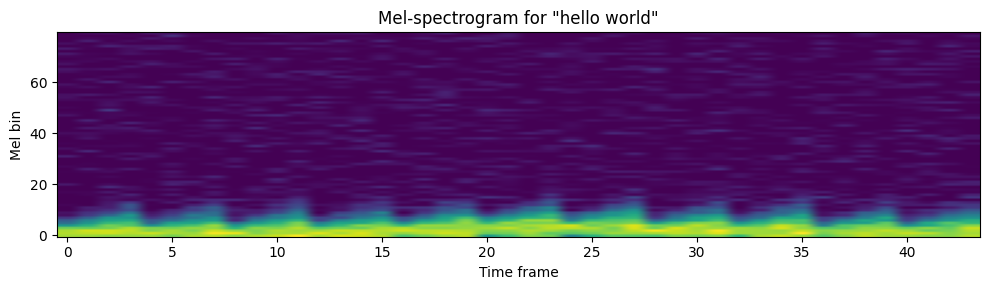

Saved toy mel example visualization


In [9]:
MEL_DIM = 80
SR = 22050  # sample rate
FRAME_LENGTH = 0.05  # 50ms (matches paper)
FRAME_SHIFT = 0.0125  # 12.5ms (matches paper)
FRAMES_PER_CHAR = 4  # mel frames per character (deterministic mapping)

def char_to_frequency(char_idx):
    """Map each character to a unique base frequency for synthetic audio."""
    return 100 + char_idx * 15  # 100Hz to ~625Hz range

def generate_mel_spectrogram(text_indices, sr=SR, mel_dim=MEL_DIM, frames_per_char=FRAMES_PER_CHAR):
    """Generate a synthetic mel-spectrogram from character indices.
    Each character produces a short sine-wave segment, and the mel-spectrogram
    captures the frequency content over time.
    """
    n_frames = len(text_indices) * frames_per_char
    mel = np.zeros((n_frames, mel_dim))
    
    for i, c_idx in enumerate(text_indices):
        freq = char_to_frequency(c_idx)
        # Each character's frames have a spectral peak around its frequency
        # Map frequency to mel bin
        mel_bin = int(freq / (sr / 2) * mel_dim)
        mel_bin = min(mel_bin, mel_dim - 1)
        
        for f in range(frames_per_char):
            frame_idx = i * frames_per_char + f
            # Create a peaked spectrum with some temporal variation
            center = mel_bin
            spread = 3 + f  # increasing spread over the character's frames
            for b in range(mel_dim):
                distance = abs(b - center)
                mel[frame_idx, b] = np.exp(-distance**2 / (2 * spread**2))
            # Add some noise for variety
            mel[frame_idx] += np.random.randn(mel_dim) * 0.05
    
    # Normalize to [0, 1]
    mel = np.clip(mel, 0, None)
    mel = mel / (mel.max() + 1e-8)
    return mel.astype(np.float32)

# Generate a few training samples
SAMPLE_TEXTS = [
    'hello world',
    'good morning',
    'how are you',
    'the quick brown fox',
    'speech synthesis is fun',
    'tacotron model works',
    'end to end learning',
    'deep learning rocks',
    'neural networks are great',
    'text to speech system',
    'attention mechanism helps',
    'character level input',
    'mel spectrogram output',
    'griffin lim algorithm',
    'highway network layers',
    'conv bank filters',
    'bidirectional gru cells',
    'sequence to sequence model',
    'generative text to speech',
    'natural sounding voice',
    'machine learning is cool',
    'artificial intelligence',
    'the cat sat on the mat',
    'a stitch in time saves nine',
    'practice makes perfect',
    'knowledge is power',
    'time and tide wait for none',
    'every cloud has a silver lining',
    'actions speak louder than words',
    'the early bird catches the worm',
]

dataset = []
for text in SAMPLE_TEXTS:
    indices = text_to_indices(text)
    if len(indices) < 2:
        continue
    mel = generate_mel_spectrogram(indices)
    # Make mel length divisible by r=2
    if mel.shape[0] % 2 != 0:
        mel = mel[:-1]
    dataset.append((indices, mel))

print(f'Dataset size: {len(dataset)} samples')
for i, (idx, mel) in enumerate(dataset[:3]):
    text = ''.join(IDX_TO_CHAR[j] for j in idx)
    print(f'  [{i}] "{text}" -> indices={len(idx)}, mel={mel.shape}')

# Visualize one example
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.imshow(dataset[0][1].T, aspect='auto', origin='lower', cmap='viridis')
ax.set_title(f'Mel-spectrogram for "{SAMPLE_TEXTS[0]}"')
ax.set_xlabel('Time frame')
ax.set_ylabel('Mel bin')
plt.tight_layout()
plt.savefig('toy_mel_example.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved toy mel example visualization')


## 10. Data Loading and Batching

We pad sequences to the max length in each batch and return tensors ready for the model.

In [10]:
def collate_batch(batch):
    """Pad a batch of (indices, mel) pairs."""
    indices_list = [item[0] for item in batch]
    mel_list = [item[1] for item in batch]
    
    max_text_len = max(len(idx) for idx in indices_list)
    max_mel_len = max(mel.shape[0] for mel in mel_list)
    # Ensure mel length is divisible by r=2
    if max_mel_len % 2 != 0:
        max_mel_len -= 1
    
    # Pad text indices
    text_batch = torch.zeros(len(batch), max_text_len, dtype=torch.long)
    for i, idx in enumerate(indices_list):
        text_batch[i, :len(idx)] = torch.tensor(idx)
    
    # Pad mel spectrograms
    mel_batch = torch.zeros(len(batch), max_mel_len, MEL_DIM)
    for i, mel in enumerate(mel_list):
        mel_len = min(mel.shape[0], max_mel_len)
        mel_batch[i, :mel_len] = torch.tensor(mel[:mel_len])
    
    return text_batch, mel_batch

# Test batching
test_batch = collate_batch(dataset[:4])
print(f'Batch: text={test_batch[0].shape}, mel={test_batch[1].shape}')

from torch.utils.data import DataLoader
dataloader = DataLoader(dataset, batch_size=8, shuffle=True, collate_fn=collate_batch, drop_last=False)
print(f'DataLoader: {len(dataloader)} batches of size 8')


Batch: text=torch.Size([4, 19]), mel=torch.Size([4, 76, 80])
DataLoader: 4 batches of size 8


## 11. Training Loop

Train with L1 loss (matching the paper) on both the mel-spectrogram prediction and
the post-net refined output. We use Adam optimizer with learning rate decay.

In [11]:
EPOCHS = 30
LR = 0.001
BATCH_SIZE = 16

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

loss_history = []
attn_history = []

model.train()
for epoch in range(EPOCHS):
    epoch_loss = 0.0
    n_batches = 0
    
    for text_batch, mel_batch in dataloader:
        text_batch = text_batch.to(DEVICE)
        mel_batch = mel_batch.to(DEVICE)
        
        # Forward pass
        mel_pred, refined_pred, attention = model(text_batch, mel_targets=mel_batch, teacher_forcing=True)
        
        # Ensure predictions match target length
        min_len = min(mel_pred.size(1), mel_batch.size(1))
        mel_pred = mel_pred[:, :min_len]
        refined_pred = refined_pred[:, :min_len]
        mel_target = mel_batch[:, :min_len]
        
        # L1 loss on both mel prediction and refined output (equal weights)
        loss_mel = F.l1_loss(mel_pred, mel_target)
        loss_refined = F.l1_loss(refined_pred, mel_target)
        loss = loss_mel + loss_refined
        
        optimizer.zero_grad()
        loss.backward()
        # Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        
        epoch_loss += loss.item()
        n_batches += 1
    
    avg_loss = epoch_loss / max(n_batches, 1)
    loss_history.append(avg_loss)
    scheduler.step()
    
    # Save attention visualization periodically
    if (epoch + 1) % 10 == 0 or epoch == 0:
        attn_history.append((epoch, attention[0].detach().cpu().numpy()))
        print(f'Epoch {epoch+1:3d}/{EPOCHS} | Loss: {avg_loss:.4f} | LR: {scheduler.get_last_lr()[0]:.5f}')

print(f'\nTraining complete. Final loss: {loss_history[-1]:.4f}')


Epoch   1/30 | Loss: 0.3775 | LR: 0.00100


Epoch  10/30 | Loss: 0.1041 | LR: 0.00050


Epoch  20/30 | Loss: 0.0720 | LR: 0.00025


Epoch  30/30 | Loss: 0.0644 | LR: 0.00013

Training complete. Final loss: 0.0644


### Training Loss Curve

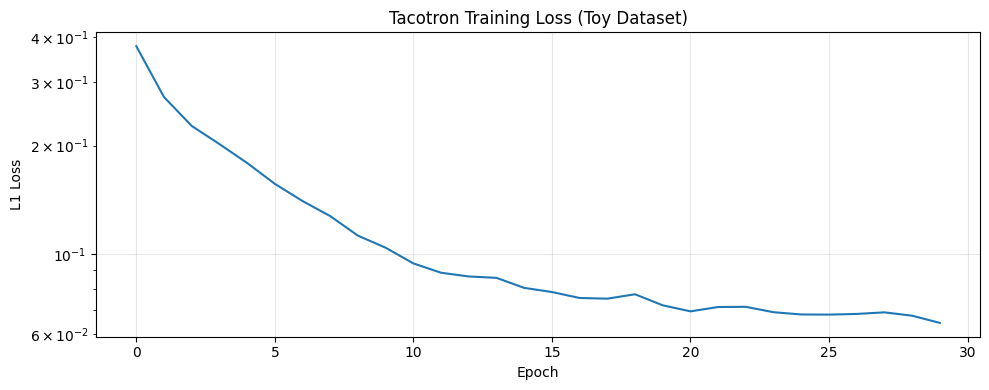

Saved training loss plot


In [12]:
plt.figure(figsize=(10, 4))
plt.plot(loss_history, linewidth=1.5)
plt.xlabel('Epoch')
plt.ylabel('L1 Loss')
plt.title('Tacotron Training Loss (Toy Dataset)')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('training_loss.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved training loss plot')


## 12. Attention Alignment Visualization

A key diagnostic for Tacotron: the attention should show a **monotonic diagonal** alignment,
meaning each decoder step attends to the correct input character. This is what the paper
demonstrates in Figure 3 — a clean alignment vs. the noisy alignment of vanilla seq2seq.

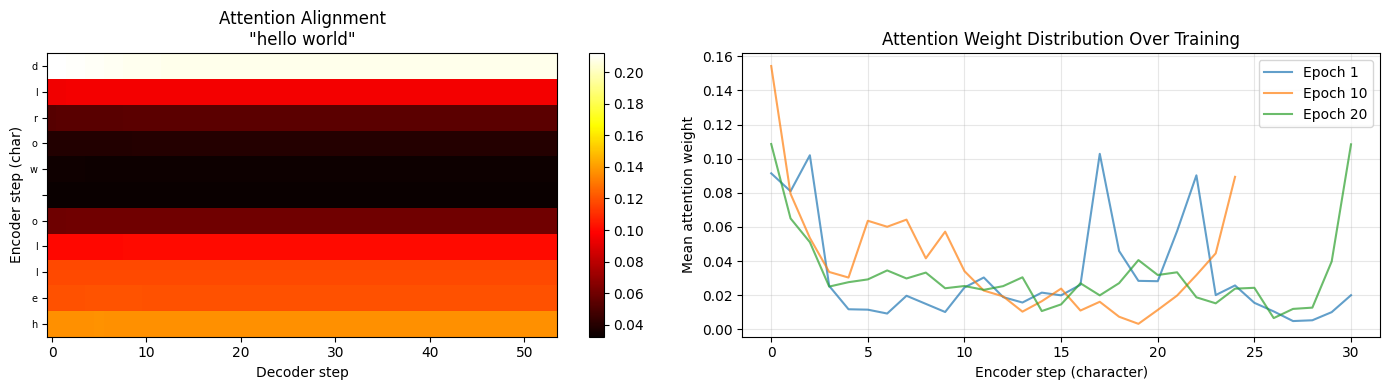

Attention shape: (54, 11)
Attention diagonal-ness: 0.0908
Saved attention alignment visualization


In [13]:
model.eval()
with torch.no_grad():
    # Run inference on a sample
    sample_idx = 0
    text_indices, mel_target = dataset[sample_idx]
    text = ''.join(IDX_TO_CHAR[j] for j in text_indices)
    
    text_tensor = torch.tensor(text_indices).unsqueeze(0).to(DEVICE)
    mel_pred, refined_pred, attention = model.inference(text_tensor, max_steps=mel_target.shape[0] + 10)
    
    # Trim prediction to target length for comparison
    min_len = min(mel_pred.size(1), mel_target.shape[0])
    mel_pred = mel_pred[:, :min_len].cpu().numpy()[0]
    refined_pred = refined_pred[:, :min_len].cpu().numpy()[0]
    attention = attention.cpu().numpy()[0]
    
    # Plot attention alignment
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    # Attention matrix
    im = axes[0].imshow(attention.T, aspect='auto', origin='lower', cmap='hot')
    axes[0].set_title(f'Attention Alignment\n"{text}"')
    axes[0].set_xlabel('Decoder step')
    axes[0].set_ylabel('Encoder step (char)')
    # Set y ticks to characters
    char_labels = [IDX_TO_CHAR[j] for j in text_indices]
    axes[0].set_yticks(range(len(char_labels)))
    axes[0].set_yticklabels(char_labels, fontsize=7)
    plt.colorbar(im, ax=axes[0])
    
    # Training attention progression
    for i, (epoch, attn) in enumerate(attn_history[:3]):
        axes[1].plot(attn.mean(axis=0), label=f'Epoch {epoch+1}', alpha=0.7)
    axes[1].set_title('Attention Weight Distribution Over Training')
    axes[1].set_xlabel('Encoder step (character)')
    axes[1].set_ylabel('Mean attention weight')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('attention_alignment.png', dpi=100, bbox_inches='tight')
    plt.show()
    print(f'Attention shape: {attention.shape}')
    print(f'Attention diagonal-ness: {np.mean(np.diag(attention[:min_len, :len(text_indices)])):.4f}')
    print('Saved attention alignment visualization')


## 13. Predicted vs. Ground-Truth Mel-Spectrogram

Compare the model's predicted mel-spectrogram against the ground truth to evaluate
how well the model learned the text-to-spectrogram mapping.

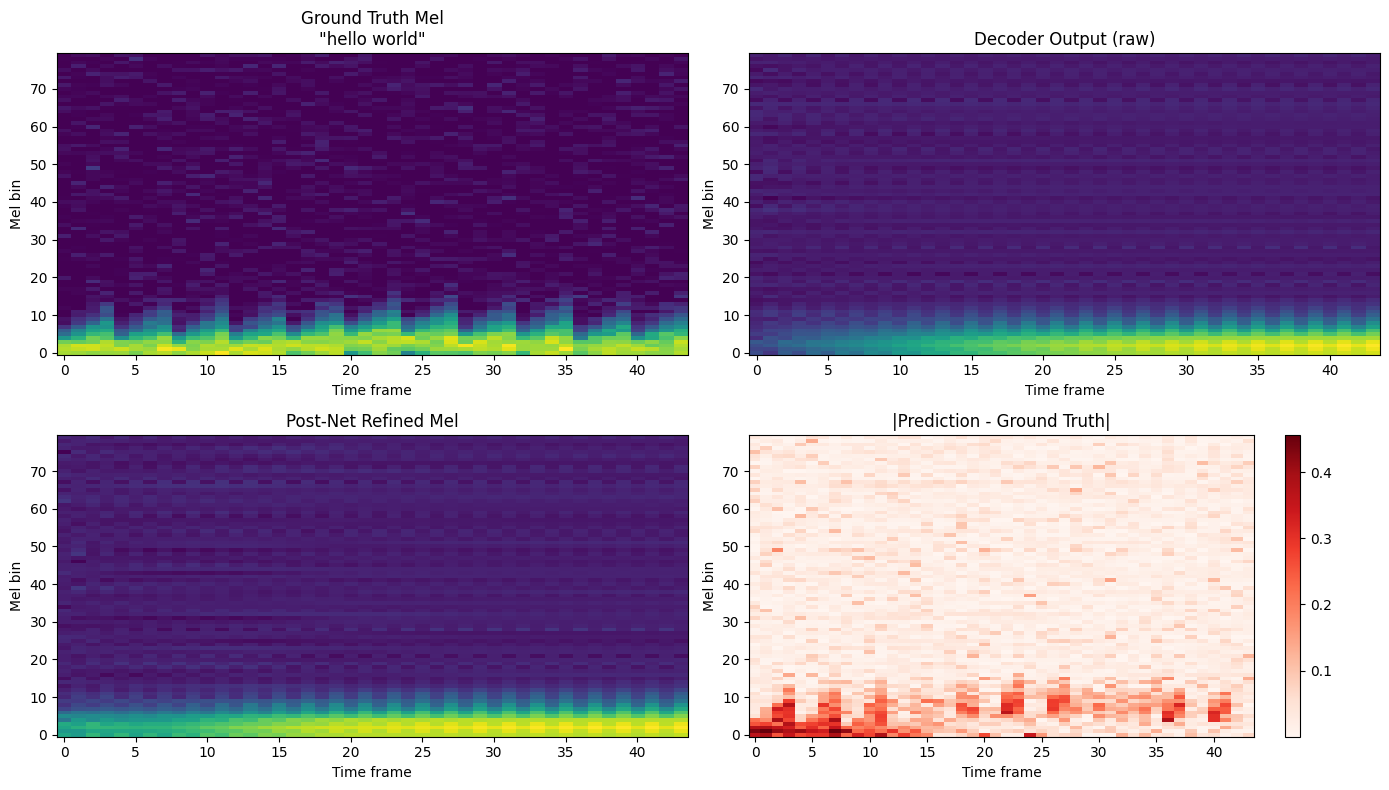

Mel L1 error: 0.0425
Saved mel comparison visualization


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Ground truth
ax = axes[0, 0]
ax.imshow(mel_target.T, aspect='auto', origin='lower', cmap='viridis')
ax.set_title(f'Ground Truth Mel\n"{text}"')
ax.set_xlabel('Time frame')
ax.set_ylabel('Mel bin')

# Raw decoder output
ax = axes[0, 1]
ax.imshow(mel_pred.T, aspect='auto', origin='lower', cmap='viridis')
ax.set_title('Decoder Output (raw)')
ax.set_xlabel('Time frame')
ax.set_ylabel('Mel bin')

# Post-net refined output
ax = axes[1, 0]
ax.imshow(refined_pred.T, aspect='auto', origin='lower', cmap='viridis')
ax.set_title('Post-Net Refined Mel')
ax.set_xlabel('Time frame')
ax.set_ylabel('Mel bin')

# Difference
ax = axes[1, 1]
diff = np.abs(refined_pred - mel_target[:min_len])
im = ax.imshow(diff.T, aspect='auto', origin='lower', cmap='Reds')
ax.set_title('|Prediction - Ground Truth|')
ax.set_xlabel('Time frame')
ax.set_ylabel('Mel bin')
plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig('mel_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

mel_l1 = np.mean(np.abs(refined_pred - mel_target[:min_len]))
print(f'Mel L1 error: {mel_l1:.4f}')
print('Saved mel comparison visualization')


## 14. Griffin-Lim Waveform Synthesis

Convert the predicted mel-spectrogram to an audio waveform using the Griffin-Lim algorithm.
The paper uses this classical signal-processing method (50 iterations) to go from
spectrogram → waveform without a neural vocoder.

Waveform shape: (11825,)
Waveform duration: 0.54s


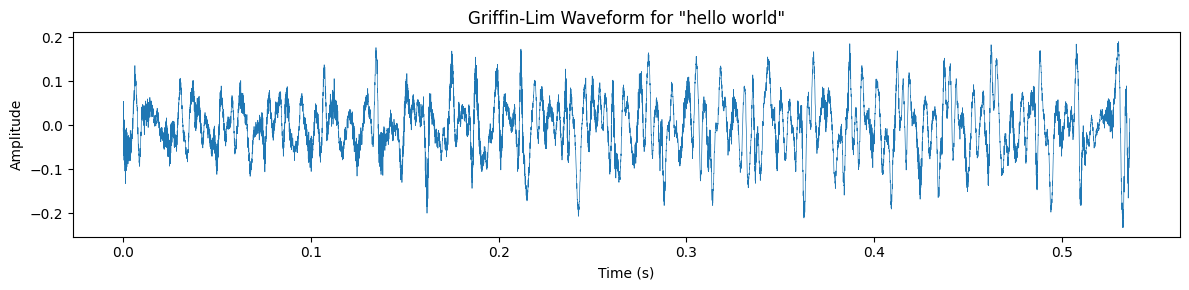

Saved waveform visualization


In [15]:
if HAS_LIBROSA:
    # Convert mel-spectrogram to linear spectrogram, then Griffin-Lim
    # In practice, the post-net would predict linear spectrogram
    # Here we approximate by inverting the mel filter bank
    
    mel_for_gl = refined_pred.T  # (mel_dim, T) -> need (T, mel_dim) for librosa
    
    # Use librosa mel inversion + Griffin-Lim
    # First, convert our normalized mel back to a magnitude spectrogram approximation
    # We use a pseudo-inverse of the mel filter bank
    mel_basis = librosa.filters.mel(sr=SR, n_fft=2048, n_mels=MEL_DIM)
    inv_mel_basis = np.linalg.pinv(mel_basis)
    
    # Approximate linear spectrogram from mel
    linear_spec = inv_mel_basis @ mel_for_gl  # (n_fft//2+1, T)
    linear_spec = np.maximum(linear_spec, 0)
    
    # Griffin-Lim reconstruction (50 iterations, matching the paper)
    waveform = librosa.griffinlim(linear_spec, n_iter=50, hop_length=int(SR * FRAME_SHIFT),
                                   win_length=int(SR * FRAME_LENGTH))
    
    print(f'Waveform shape: {waveform.shape}')
    print(f'Waveform duration: {len(waveform) / SR:.2f}s')
    
    # Plot waveform
    plt.figure(figsize=(12, 3))
    time_axis = np.arange(len(waveform)) / SR
    plt.plot(time_axis, waveform, linewidth=0.5)
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.title(f'Griffin-Lim Waveform for "{text}"')
    plt.tight_layout()
    plt.savefig('waveform.png', dpi=100, bbox_inches='tight')
    plt.show()
    print('Saved waveform visualization')
else:
    # Simple numpy-based waveform: use IFFT on the magnitude spectrogram
    # This is a rough approximation without Griffin-Lim's iterative phase estimation
    mel_for_gl = refined_pred  # (T, mel_dim)
    
    # Create a rough spectrogram and do simple ISTFT with random phase
    n_fft = 2048
    hop = int(SR * FRAME_SHIFT)
    win = int(SR * FRAME_LENGTH)
    
    # Approximate linear spectrogram from mel (simple mapping)
    n_bins = n_fft // 2 + 1
    linear_spec = np.zeros((mel_for_gl.shape[0], n_bins), dtype=complex)
    for t in range(mel_for_gl.shape[0]):
        # Spread mel energy across linear bins
        for b in range(MEL_DIM):
            lin_bin = int(b * n_bins / MEL_DIM)
            if lin_bin < n_bins:
                linear_spec[t, lin_bin] = mel_for_gl[t, b] + 1e-8
    
    # Simple iterative phase estimation (simplified Griffin-Lim)
    for _ in range(10):
        # ISTFT
        frames = np.fft.irfft(linear_spec, n=n_fft, axis=1)
        # Apply window
        window = np.hanning(n_fft)
        frames = frames * window
        # Overlap-add
        waveform_len = (mel_for_gl.shape[0] - 1) * hop + n_fft
        waveform = np.zeros(waveform_len)
        for t in range(mel_for_gl.shape[0]):
            start = t * hop
            waveform[start:start + n_fft] += frames[t]
        # Recompute STFT
        for t in range(mel_for_gl.shape[0]):
            start = t * hop
            frame = waveform[start:start + n_fft] * window
            linear_spec[t] = np.fft.rfft(frame)
        # Keep magnitude, update phase
        magnitude = np.abs(linear_spec)
        # Re-apply target magnitude
        for b in range(MEL_DIM):
            lin_bin = int(b * n_bins / MEL_DIM)
            if lin_bin < n_bins:
                magnitude[:, lin_bin] = mel_for_gl[:, b] + 1e-8
        linear_spec = magnitude * np.exp(1j * np.angle(linear_spec))
    
    # Final ISTFT
    frames = np.fft.irfft(linear_spec, n=n_fft, axis=1)
    window = np.hanning(n_fft)
    frames = frames * window
    waveform_len = (mel_for_gl.shape[0] - 1) * hop + n_fft
    waveform = np.zeros(waveform_len)
    for t in range(mel_for_gl.shape[0]):
        start = t * hop
        waveform[start:start + n_fft] += frames[t]
    
    # Normalize
    waveform = waveform / (np.max(np.abs(waveform)) + 1e-8) * 0.9
    
    print(f'Waveform shape: {waveform.shape}')
    print(f'Waveform duration: {len(waveform) / SR:.2f}s')
    
    plt.figure(figsize=(12, 3))
    time_axis = np.arange(len(waveform)) / SR
    plt.plot(time_axis, waveform, linewidth=0.5)
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.title(f'Synthesized Waveform for "{text}"')
    plt.tight_layout()
    plt.savefig('waveform.png', dpi=100, bbox_inches='tight')
    plt.show()
    print('Saved waveform visualization (numpy-based, no librosa)')


## 15. Summary and Key Takeaways

This notebook demonstrated the **Tacotron architecture** from scratch:

1. **CBHG module** — The convolution bank + highway network + bidirectional GRU captures both local
   (n-gram-like) and sequential features. It's used in both the encoder and post-processing net.

2. **Attention-based seq2seq decoder** — Maps variable-length character sequences to mel-spectrogram
   frames. The content-based tanh attention learns a monotonic alignment between text and speech.

3. **Reduction factor r=2** — Predicting 2 frames per decoder step is crucial for fast, stable
   attention convergence. Without it, the attention gets stuck on individual characters.

4. **Pre-net dropout** — The 50% dropout in the pre-net is a key generalization technique.
   It provides noise that helps the model handle the multi-modal nature of speech.

5. **Post-processing net** — Bidirectional refinement of the decoded spectrogram improves harmonic
   resolution and reduces synthesis artifacts.

6. **Griffin-Lim** — A simple non-neural method to convert spectrograms to waveforms. While it
   introduces some artifacts, Tacotron 2 later replaced it with a WaveNet neural vocoder.

**Deliberate simplifications:** We used a toy dataset (synthetic mel-spectrograms from character-
to-frequency mapping), reduced CBHG sizes, and trained for fewer epochs than the paper. The goal
was architectural demonstration, not natural speech quality — the real Tacotron was trained on
24.6 hours of professional speech for millions of steps.

**Paper:** [arXiv:1703.10135](https://arxiv.org/abs/1703.10135) | **Demo:** [google.github.io/tacotron](https://google.github.io/tacotron/)


In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')
